# Red neuronal funcional con cabeza KAN B-spline

Este notebook construye y verifica la arquitectura exigida para reconstruir una curva terrestre a partir de una curva satelital. Sigue la guía de clase para PyTorch, entrenamiento reproducible, cabezas intercambiables y decodificación FPCA, pero reemplaza la FastKAN gaussiana del ejemplo por la **KAN B-spline exigida en el proyecto**.

**Alcance actual:** arquitectura, álgebra funcional, control de parámetros y pruebas sintéticas. No se entrenan datos reales hasta contar con pares estación–píxel, altitud, ONI y curvas finales aprobadas por el preprocesamiento.


In [ ]:
# Verificación reproducible: no reinstala paquetes presentes ni instala sin autorización.
from importlib.util import find_spec
import subprocess
import sys

INSTALAR_FALTANTES = False  # Cambiar a True únicamente si se autoriza instalar en este entorno.
PAQUETES_REQUERIDOS = {'pandas': 'pandas', 'numpy': 'numpy', 'matplotlib': 'matplotlib', 'torch': 'torch'}
faltantes = {modulo: paquete for modulo, paquete in PAQUETES_REQUERIDOS.items()
             if find_spec(modulo) is None}

if faltantes and INSTALAR_FALTANTES:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *faltantes.values()])
    faltantes = {modulo: paquete for modulo, paquete in PAQUETES_REQUERIDOS.items()
                 if find_spec(modulo) is None}

if faltantes:
    comando = f"{sys.executable} -m pip install {' '.join(faltantes.values())}"
    raise ModuleNotFoundError(
        f"Faltan dependencias: {faltantes}. No se instalaron automáticamente. "
        f"Autorice la instalación o ejecute: {comando}"
    )

versiones = {modulo: __import__(modulo).__version__
             for modulo in PAQUETES_REQUERIDOS
             if hasattr(__import__(modulo), '__version__')}
print('Dependencias verificadas:', versiones)


## 1. Contrato metodológico

La red tiene tres bloques que permanecerán iguales durante la ablación, excepto por la cabeza:

1. **Codificador funcional:** representa la curva satelital mediante coeficientes B-spline y calcula $z=AWc$ con 6–8 neuronas funcionales.
2. **Cabeza:** lineal, MLP o KAN; produce entre 4 y 6 puntajes FPCA.
3. **Decodificador FPCA congelado:** reconstruye los coeficientes de la curva terrestre.

La pérdida principal es la distancia funcional $L^2$ calculada con la matriz de Gram, más una penalización de rugosidad sobre las funciones de peso del codificador. KAN y MLP deben diferir como máximo 10 % en parámetros y usar el mismo presupuesto de entrenamiento.

Las funciones de esta libreta no consultan prueba para seleccionar bases, componentes, anchos, épocas ni hiperparámetros.


In [1]:
%matplotlib inline
from dataclasses import dataclass
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display, Markdown

SEED = 2026
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(1)

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def count_params(module, trainable_only=False):
    params = (p for p in module.parameters() if (p.requires_grad or not trainable_only))
    return sum(p.numel() for p in params)

set_seed()
print('Dispositivo:', DEVICE)
print('PyTorch:', torch.__version__)


Dispositivo: cpu
PyTorch: 2.13.0+cpu


## 2. Base B-spline manual y matriz de Gram

Se implementa la recurrencia de Cox–de Boor directamente con operaciones de PyTorch. No se usa `scipy.interpolate.BSpline` ni una librería KAN. La matriz de Gram

$$W=\int_0^1 \phi(t)\phi(t)^\top\,dt$$

se aproxima mediante cuadratura trapezoidal sobre una malla densa. Esta matriz introduce el producto interno funcional y evita tratar los coeficientes como si fueran variables independientes.


,control,valor
0,mínimo de la base,0.000000e+00
1,máximo error suma=1,4.440892e-16
2,simetría de W,3.469447e-18
3,mínimo autovalor W,3.938583e-03


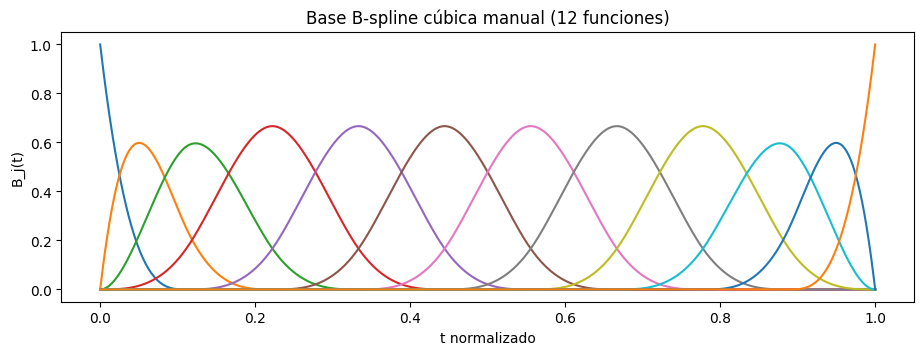

In [2]:
def open_uniform_knots(n_basis, degree=3, low=0.0, high=1.0, *, device=None, dtype=torch.float32):
    if n_basis <= degree:
        raise ValueError('n_basis debe ser mayor que degree')
    n_internal = n_basis - degree - 1
    if n_internal > 0:
        internal = torch.linspace(low, high, n_internal + 2, device=device, dtype=dtype)[1:-1]
    else:
        internal = torch.empty(0, device=device, dtype=dtype)
    return torch.cat([
        torch.full((degree + 1,), low, device=device, dtype=dtype),
        internal,
        torch.full((degree + 1,), high, device=device, dtype=dtype),
    ])

def bspline_basis_torch(x, knots, degree=3):
    """Evalúa todas las B-splines; x puede tener cualquier forma y se aplana temporalmente."""
    original_shape = x.shape
    x_flat = x.reshape(-1)
    eps = 10 * torch.finfo(x_flat.dtype).eps
    x_eval = torch.clamp(x_flat, min=float(knots[0]), max=float(knots[-1]) - eps)
    B = ((x_eval[:, None] >= knots[:-1]) & (x_eval[:, None] < knots[1:])).to(x_flat.dtype)
    for p in range(1, degree + 1):
        n_cols = len(knots) - p - 1
        left_den = knots[p:p + n_cols] - knots[:n_cols]
        right_den = knots[p + 1:p + 1 + n_cols] - knots[1:1 + n_cols]
        left_num = x_eval[:, None] - knots[:n_cols]
        right_num = knots[p + 1:p + 1 + n_cols] - x_eval[:, None]
        left = torch.where(left_den.abs() > 0, left_num / left_den.clamp_min(eps), torch.zeros_like(left_num)) * B[:, :n_cols]
        right = torch.where(right_den.abs() > 0, right_num / right_den.clamp_min(eps), torch.zeros_like(right_num)) * B[:, 1:n_cols + 1]
        B = left + right
    return B.reshape(*original_shape, B.shape[-1])

def gram_matrix_bspline(n_basis, degree=3, n_quad=2001, dtype=torch.float64):
    knots = open_uniform_knots(n_basis, degree, dtype=dtype)
    grid = torch.linspace(0.0, 1.0, n_quad, dtype=dtype)
    Phi = bspline_basis_torch(grid, knots, degree)
    dx = 1.0 / (n_quad - 1)
    weights = torch.full((n_quad,), dx, dtype=dtype)
    weights[[0, -1]] *= 0.5
    W = Phi.T @ (weights[:, None] * Phi)
    return grid, Phi, knots, W

N_BASIS = 12
DEGREE = 3
grid_t, PHI, knots_t, W = gram_matrix_bspline(N_BASIS, DEGREE)
control_base = pd.DataFrame({
    'control': ['mínimo de la base', 'máximo error suma=1', 'simetría de W', 'mínimo autovalor W'],
    'valor': [
        float(PHI.min()),
        float((PHI.sum(1) - 1).abs().max()),
        float((W - W.T).abs().max()),
        float(torch.linalg.eigvalsh(W).min()),
    ]
})
display(control_base)

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(grid_t, PHI)
ax.set(title=f'Base B-spline cúbica manual ({N_BASIS} funciones)', xlabel='t normalizado', ylabel='B_j(t)')
plt.show()


## 3. Conversión de curvas a coeficientes

Una curva observada en una malla común se aproxima por $X(t)\approx\phi(t)^\top c$. Los coeficientes se obtienen por mínimos cuadrados. Cuando existan faltantes, se usarán únicamente las filas observadas de la matriz de diseño; no se rellenará primero la precipitación diaria.


In [3]:
def curves_to_coefficients(curves, design, observed=None, ridge=1e-8):
    curves = np.asarray(curves, dtype=np.float64)
    design = np.asarray(design, dtype=np.float64)
    if curves.ndim == 1:
        curves = curves[None, :]
    if observed is None:
        observed = np.isfinite(curves)
    coeffs = []
    for y, mask in zip(curves, observed):
        valid = np.asarray(mask) & np.isfinite(y)
        B = design[valid]
        target = y[valid]
        if valid.sum() < design.shape[1]:
            coeffs.append(np.full(design.shape[1], np.nan))
            continue
        lhs = B.T @ B + ridge * np.eye(B.shape[1])
        coeffs.append(np.linalg.solve(lhs, B.T @ target))
    return np.asarray(coeffs)

# Verificación con coeficientes conocidos
rng = np.random.default_rng(SEED)
c_known = rng.normal(size=(5, N_BASIS))
y_known = c_known @ PHI.numpy().T
c_recovered = curves_to_coefficients(y_known, PHI.numpy())
print('Error máximo al recuperar coeficientes conocidos:', np.max(np.abs(c_known - c_recovered)))


Error máximo al recuperar coeficientes conocidos: 1.468837496076958e-09


## 4. Codificador con neuronas funcionales

Cada fila de `weight_coeffs` contiene los coeficientes $a_k$ de una función de peso $w_k(t)$. Para un lote de coeficientes satelitales $c$, el codificador calcula

$$z=cWA^\top,$$

equivalente a $z_k=\int w_k(t)X(t)dt$. La altitud y el ONI se agregan después; ambos deberán estandarizarse usando únicamente entrenamiento.


In [4]:
class FunctionalEncoder(nn.Module):
    def __init__(self, n_basis, n_neurons, gram):
        super().__init__()
        self.n_basis = n_basis
        self.n_neurons = n_neurons
        self.weight_coeffs = nn.Parameter(torch.empty(n_neurons, n_basis))
        nn.init.xavier_uniform_(self.weight_coeffs)
        self.register_buffer('gram', torch.as_tensor(gram, dtype=torch.float32))

    def forward(self, satellite_coeffs):
        return satellite_coeffs @ self.gram @ self.weight_coeffs.T

    def roughness(self):
        second_diff = self.weight_coeffs[:, 2:] - 2 * self.weight_coeffs[:, 1:-1] + self.weight_coeffs[:, :-2]
        return second_diff.square().mean()

    @torch.no_grad()
    def weight_functions(self, design):
        return design @ self.weight_coeffs.T

encoder_demo = FunctionalEncoder(N_BASIS, n_neurons=8, gram=W.float())
c_demo = torch.randn(4, N_BASIS)
z_demo = encoder_demo(c_demo)
print('Forma de c:', tuple(c_demo.shape), '→ forma de z:', tuple(z_demo.shape))
print('Rugosidad inicial:', float(encoder_demo.roughness()))


Forma de c: (4, 12) → forma de z: (4, 8)
Rugosidad inicial: 0.666048526763916


C:\Users\fedeg\AppData\Local\Temp\ipykernel_52868\1360094545.py:25: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:823.)
  print('Rugosidad inicial:', float(encoder_demo.roughness()))


## 5. FPCA ponderada y decodificador congelado

La FPCA se ajustará exclusivamente con los coeficientes terrestres de entrenamiento. Se factoriza $W=LL^\top$ para que la SVD respete la geometría $L^2$. Las autofunciones quedan ortonormales respecto a $W$, no respecto al producto punto ordinario.


In [5]:
def fit_weighted_fpca(coeffs, gram, n_components):
    C = torch.as_tensor(coeffs, dtype=torch.float64)
    G = torch.as_tensor(gram, dtype=torch.float64)
    mean = C.mean(0)
    L = torch.linalg.cholesky(G)
    Z = (C - mean) @ L
    _, singular, Vh = torch.linalg.svd(Z, full_matrices=False)
    basis_coeffs = Vh[:n_components] @ torch.linalg.inv(L)
    signs = torch.sign(basis_coeffs.sum(1, keepdim=True) + 1e-12)
    basis_coeffs = basis_coeffs * signs
    explained = singular.square() / singular.square().sum()
    return {
        'mean_coeffs': mean.float(),
        'basis_coeffs': basis_coeffs.float(),
        'explained': explained.float(),
    }

class FPCACoefficientDecoder(nn.Module):
    def __init__(self, n_basis, n_components, gram):
        super().__init__()
        self.register_buffer('mean_coeffs', torch.zeros(n_basis))
        self.register_buffer('basis_coeffs', torch.zeros(n_components, n_basis))
        self.register_buffer('gram', torch.as_tensor(gram, dtype=torch.float32))

    def set_fpca(self, fpca):
        self.mean_coeffs.copy_(fpca['mean_coeffs'])
        self.basis_coeffs.copy_(fpca['basis_coeffs'])
        return self

    def forward(self, scores):
        return self.mean_coeffs + scores @ self.basis_coeffs

    def project(self, coeffs):
        centered = coeffs - self.mean_coeffs
        return centered @ self.gram @ self.basis_coeffs.T

# Prueba algebraica con curvas sintéticas suaves
synthetic_ground_coeffs = rng.normal(size=(300, N_BASIS))
synthetic_ground_coeffs = np.cumsum(synthetic_ground_coeffs, axis=1) / 5
fpca_demo = fit_weighted_fpca(synthetic_ground_coeffs, W, n_components=5)
decoder_demo = FPCACoefficientDecoder(N_BASIS, 5, W.float()).set_fpca(fpca_demo)
ortho_error = decoder_demo.basis_coeffs @ decoder_demo.gram @ decoder_demo.basis_coeffs.T - torch.eye(5)
print('Error máximo de ortonormalidad respecto a W:', float(ortho_error.abs().max()))
print('Varianza explicada acumulada M=5:', float(fpca_demo['explained'][:5].sum()))


Error máximo de ortonormalidad respecto a W: 4.936009645462036e-08
Varianza explicada acumulada M=5: 0.9920588135719299


## 6. Capa KAN con B-splines

Cada arista aprende

$$\phi_{oi}(x)=w_{b,oi}\operatorname{SiLU}(x)+w_{s,oi}\sum_j c_{oij}B_j(x).$$

La implementación conserva la filosofía de la guía del docente —una función aprendible por arista y evaluación vectorizada—, pero usa las bases exigidas en el documento del proyecto.


In [6]:
class KANBSplineLayer(nn.Module):
    def __init__(self, in_features, out_features, n_basis=10, degree=3, grid_range=(-2.5, 2.5),
                 use_layernorm=True, coeff_init_std=0.03):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.n_basis = n_basis
        self.degree = degree
        self.grid_range = grid_range
        self.norm = nn.LayerNorm(in_features) if use_layernorm else nn.Identity()
        knots = open_uniform_knots(n_basis, degree, grid_range[0], grid_range[1])
        self.register_buffer('knots', knots)
        self.base_weight = nn.Parameter(torch.empty(out_features, in_features))
        self.spline_scale = nn.Parameter(torch.ones(out_features, in_features))
        self.spline_coeff = nn.Parameter(torch.randn(out_features, in_features, n_basis) * coeff_init_std)
        self.bias = nn.Parameter(torch.zeros(out_features))
        nn.init.kaiming_uniform_(self.base_weight, a=math.sqrt(5))

    def basis(self, x):
        return bspline_basis_torch(x, self.knots, self.degree)

    def forward(self, x):
        x = self.norm(x)
        base = F.silu(x) @ self.base_weight.T
        spline_raw = torch.einsum('big,oig->bo', self.basis(x), self.spline_coeff)
        # La escala es por arista, por eso se aplica dentro de la suma sobre entradas.
        spline = torch.einsum('big,oig,oi->bo', self.basis(x), self.spline_coeff, self.spline_scale)
        return base + spline + self.bias

    @torch.no_grad()
    def edge_function(self, out_idx, in_idx, x_grid):
        B = bspline_basis_torch(x_grid, self.knots, self.degree)
        return (self.base_weight[out_idx, in_idx] * F.silu(x_grid)
                + self.spline_scale[out_idx, in_idx] * (B @ self.spline_coeff[out_idx, in_idx]))

    def spline_l1(self):
        return self.spline_coeff.abs().mean()

class LinearHead(nn.Module):
    def __init__(self, n_in, n_out):
        super().__init__()
        self.net = nn.Linear(n_in, n_out)
    def forward(self, x):
        return self.net(x)

class MLPHead(nn.Module):
    def __init__(self, n_in, n_out, hidden, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_in, hidden), nn.GELU(), nn.Dropout(dropout), nn.Linear(hidden, n_out))
    def forward(self, x):
        return self.net(x)

class KANHead(nn.Module):
    def __init__(self, n_in, n_out, hidden, n_basis=10, dropout=0.0):
        super().__init__()
        self.project = nn.Linear(n_in, hidden)
        self.dropout = nn.Dropout(dropout)
        self.kan = KANBSplineLayer(hidden, n_out, n_basis=n_basis, use_layernorm=True)
    def forward(self, x):
        return self.kan(self.dropout(self.project(x)))


## 7. Igualación de parámetros entre KAN y MLP

La cabeza lineal representa otro modelo y puede tener menos parámetros. La restricción de ±10 % aplica entre KAN y MLP. El ancho de cada una se selecciona antes del entrenamiento real y se congela para las tres semillas.


In [7]:
def find_matched_heads(n_in, n_out, kan_hidden_candidates=range(4, 33), mlp_hidden_candidates=range(4, 257), n_basis=10):
    rows = []
    for hk in kan_hidden_candidates:
        pk = count_params(KANHead(n_in, n_out, hk, n_basis=n_basis))
        for hm in mlp_hidden_candidates:
            pm = count_params(MLPHead(n_in, n_out, hm))
            diff = 100 * abs(pk - pm) / max(pk, pm)
            rows.append((diff, hk, hm, pk, pm))
    return (pd.DataFrame(rows, columns=['diferencia_pct', 'hidden_kan', 'hidden_mlp', 'params_kan', 'params_mlp'])
            .sort_values(['diferencia_pct', 'params_kan'], kind='stable'))

N_FUNCTIONAL = 8
N_COVARIATES = 2  # altitud y ONI
N_INPUT_HEAD = N_FUNCTIONAL + N_COVARIATES
N_FPCA = 5
matched = find_matched_heads(N_INPUT_HEAD, N_FPCA)
selected_match = matched.iloc[0]
display(matched.head(10).reset_index(drop=True))
print('Pareja seleccionada:', selected_match.to_dict())
assert selected_match.diferencia_pct <= 10.0


,diferencia_pct,hidden_kan,hidden_mlp,params_kan,params_mlp
0,0.000000,16,73,1173,1173
1,0.000000,32,146,2341,2341
2,0.054645,25,114,1830,1829
3,0.059347,23,105,1684,1685
4,0.091033,30,137,2195,2197
5,0.151057,9,41,662,661
6,0.151630,18,82,1319,1317
7,0.151822,27,123,1976,1973
8,0.193424,7,32,516,517
9,0.194363,14,64,1027,1029


Pareja seleccionada: {'diferencia_pct': 0.0, 'hidden_kan': 16.0, 'hidden_mlp': 73.0, 'params_kan': 1173.0, 'params_mlp': 1173.0}


## 8. Red completa y pérdida funcional

El decodificador devuelve coeficientes B-spline terrestres. Así, la pérdida integrada se calcula exactamente en el espacio de coeficientes con $W$. Se modelará $\sqrt{P}$ o $\log(1+P)$; la elección se hará con entrenamiento/validación. Al volver a milímetros se recortará el dominio transformado a valores no negativos y se reportará el porcentaje recortado.


In [8]:
class FunctionalRainNetwork(nn.Module):
    def __init__(self, gram, decoder, head_kind='linear', n_functional=8,
                 kan_hidden=8, mlp_hidden=32, kan_basis=10):
        super().__init__()
        n_basis = gram.shape[0]
        self.encoder = FunctionalEncoder(n_basis, n_functional, gram)
        n_in = n_functional + 2
        n_out = decoder.basis_coeffs.shape[0]
        if head_kind == 'linear':
            self.head = LinearHead(n_in, n_out)
        elif head_kind == 'mlp':
            self.head = MLPHead(n_in, n_out, mlp_hidden)
        elif head_kind == 'kan':
            self.head = KANHead(n_in, n_out, kan_hidden, n_basis=kan_basis)
        else:
            raise ValueError(head_kind)
        self.decoder = decoder
        for p in self.decoder.parameters():
            p.requires_grad_(False)

    def forward(self, satellite_coeffs, covariates, return_scores=False):
        z = self.encoder(satellite_coeffs)
        scores = self.head(torch.cat([z, covariates], dim=1))
        ground_coeffs = self.decoder(scores)
        return (ground_coeffs, scores, z) if return_scores else ground_coeffs

def functional_l2_loss(pred_coeffs, true_coeffs, gram):
    diff = pred_coeffs - true_coeffs
    return torch.einsum('bi,ij,bj->b', diff, gram, diff).mean()

def total_training_loss(model, pred_coeffs, true_coeffs, lambda_rough=1e-3, lambda_kan_l1=0.0):
    loss_l2 = functional_l2_loss(pred_coeffs, true_coeffs, model.encoder.gram)
    rough = model.encoder.roughness()
    kan_l1 = torch.tensor(0.0, device=pred_coeffs.device)
    if hasattr(model.head, 'kan'):
        kan_l1 = model.head.kan.spline_l1()
    total = loss_l2 + lambda_rough * rough + lambda_kan_l1 * kan_l1
    return total, {'l2': loss_l2.detach(), 'rugosidad': rough.detach(), 'kan_l1': kan_l1.detach()}

def inverse_rain_transform(values, kind='sqrt'):
    clipped = values < 0
    safe = torch.clamp(values, min=0)
    if kind == 'sqrt':
        mm = safe.square()
    elif kind == 'log1p':
        mm = torch.expm1(safe)
    else:
        raise ValueError(kind)
    return mm, 100 * clipped.float().mean()

hk = int(selected_match.hidden_kan)
hm = int(selected_match.hidden_mlp)
dec_for_models = FPCACoefficientDecoder(N_BASIS, N_FPCA, W.float()).set_fpca(fpca_demo)
models_demo = {
    'lineal': FunctionalRainNetwork(W.float(), dec_for_models, 'linear', N_FUNCTIONAL),
    'MLP': FunctionalRainNetwork(W.float(), dec_for_models, 'mlp', N_FUNCTIONAL, mlp_hidden=hm),
    'KAN': FunctionalRainNetwork(W.float(), dec_for_models, 'kan', N_FUNCTIONAL, kan_hidden=hk),
}
param_table = pd.DataFrame([
    {'modelo': name, 'params_totales': count_params(model), 'params_cabeza': count_params(model.head),
     'params_codificador': count_params(model.encoder)}
    for name, model in models_demo.items()
]).set_index('modelo')
display(param_table)


,params_totales,params_cabeza,params_codificador
modelo,,,
lineal,151,55,96
MLP,1269,1173,96
KAN,1269,1173,96


## 9. Verificación sintética obligatoria de la KAN

Antes de usar lluvia real se comprueba que una capa KAN recupere una función aditiva conocida. La prueba se considera aprobada únicamente si el RMSE sobre puntos no usados en entrenamiento es menor o igual a $10^{-2}$.


RMSE sintético = 0.000489 → prueba APROBADA


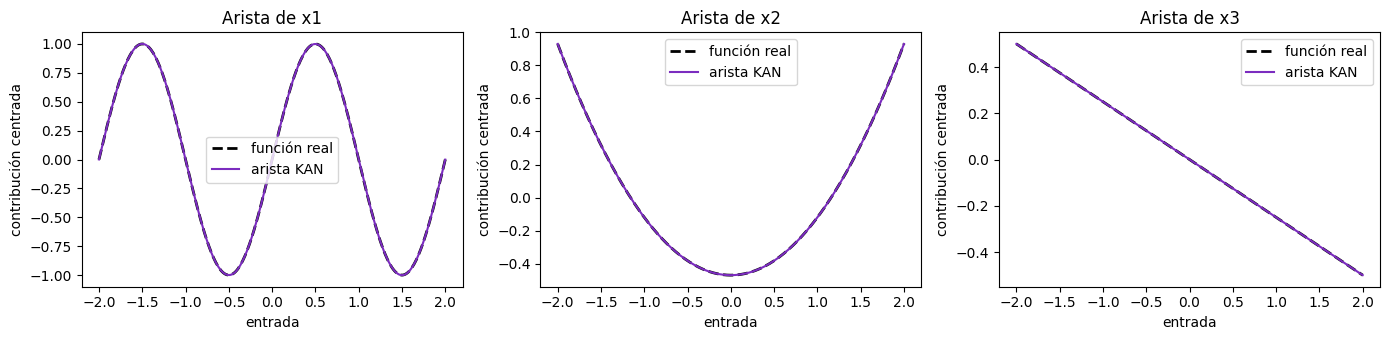

In [9]:
set_seed(17)
n_train, n_test = 1200, 400
X_all = torch.rand(n_train + n_test, 3) * 4 - 2
y_all = (torch.sin(math.pi * X_all[:, 0]) + 0.35 * X_all[:, 1].square() - 0.25 * X_all[:, 2])[:, None]
Xtr, Xte = X_all[:n_train], X_all[n_train:]
ytr, yte = y_all[:n_train], y_all[n_train:]

kan_synthetic = KANBSplineLayer(3, 1, n_basis=18, degree=3, grid_range=(-2.05, 2.05), use_layernorm=False)
optimizer = torch.optim.Adam(kan_synthetic.parameters(), lr=8e-3)
history = []
for epoch in range(2200):
    optimizer.zero_grad()
    pred = kan_synthetic(Xtr)
    loss = F.mse_loss(pred, ytr) + 1e-7 * kan_synthetic.spline_l1()
    loss.backward()
    optimizer.step()
    history.append(float(loss.detach()))

with torch.no_grad():
    pred_test = kan_synthetic(Xte)
    rmse_synthetic = float(torch.sqrt(F.mse_loss(pred_test, yte)))

estado_sintetico = 'APROBADA' if rmse_synthetic <= 1e-2 else 'NO APROBADA'
print(f'RMSE sintético = {rmse_synthetic:.6f} → prueba {estado_sintetico}')
assert rmse_synthetic <= 1e-2, 'La KAN no supera todavía el umbral exigido.'

grid = torch.linspace(-2, 2, 300)
truths = [torch.sin(math.pi * grid), 0.35 * grid.square(), -0.25 * grid]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for j, ax in enumerate(axes):
    learned = kan_synthetic.edge_function(0, j, grid)
    learned = learned - learned.mean()
    truth = truths[j] - truths[j].mean()
    ax.plot(grid, truth, 'k--', lw=2, label='función real')
    ax.plot(grid, learned, color='#7b2cbf', label='arista KAN')
    ax.set(title=f'Arista de x{j+1}', xlabel='entrada', ylabel='contribución centrada')
    ax.legend()
plt.tight_layout()
plt.show()


## 10. Equivalencia de la cabeza lineal y la regresión funcional

Sin covariables, una cabeza lineal produce $s=zB^\top+b$. Al sustituir $z=cWA^\top$ y decodificar con FPCA:

$$\hat c_y=\mu+b\Psi+c_xWA^\top B^\top\Psi.$$

Esto es una regresión función a función de rango bajo. La siguiente prueba calcula la salida por ambos caminos y exige una diferencia máxima no superior a $10^{-4}$.


In [10]:
set_seed(33)
dtype = torch.float64
batch = 20
c_x = torch.randn(batch, N_BASIS, dtype=dtype)
A = torch.randn(N_FUNCTIONAL, N_BASIS, dtype=dtype)
B_linear = torch.randn(N_FPCA, N_FUNCTIONAL, dtype=dtype)
bias_scores = torch.randn(N_FPCA, dtype=dtype)
psi = fpca_demo['basis_coeffs'].to(dtype)
mu_fpca = fpca_demo['mean_coeffs'].to(dtype)
W64 = W.to(dtype)

z = c_x @ W64 @ A.T
scores = z @ B_linear.T + bias_scores
via_red = mu_fpca + scores @ psi

intercept = mu_fpca + bias_scores @ psi
operador_rango_bajo = A.T @ B_linear.T @ psi
via_regresion = intercept + c_x @ W64 @ operador_rango_bajo
equivalence_max_diff = float((via_red - via_regresion).abs().max())
print(f'Diferencia máxima red lineal vs regresión funcional = {equivalence_max_diff:.3e}')
assert equivalence_max_diff <= 1e-4


Diferencia máxima red lineal vs regresión funcional = 1.776e-15


## 11. Protocolo de entrenamiento real

Cuando existan pares válidos, el flujo será:

1. Ajustar transformación de lluvia, base B-spline, estandarización de altitud/ONI y FPCA usando **solo 1981–1995**.
2. Elegir número de bases, $M$, regularización, anchos y parada temprana con **1996–2000**.
3. Congelar todas las decisiones y evaluar una sola vez en **2001–2003** y estaciones reservadas.
4. Entrenar cada cabeza con tres semillas y el mismo máximo de épocas, paciencia y número de pruebas de hiperparámetros.
5. Comparar también contra la curva satelital sin corregir.

Las métricas finales serán error $L^2$ relativo, KGE, sesgo anual y error en la fecha de los dos picos, con bootstrap pareado y resultados por fase ENSO.


In [11]:
readiness = pd.DataFrame([
    ['Arquitectura funcional z=AWc', 'lista', 'Implementada y verificada dimensionalmente'],
    ['Matriz de Gram por cuadratura', 'lista', 'B-spline manual y controles numéricos'],
    ['Decodificador FPCA congelado', 'lista', 'FPCA ponderada; falta ajustarla con train real'],
    ['KAN B-spline', 'lista', f'Prueba sintética RMSE={rmse_synthetic:.6f}'],
    ['Equivalencia cabeza lineal', 'lista', f'diferencia máxima={equivalence_max_diff:.3e}'],
    ['Parámetros KAN–MLP', 'lista', f'diferencia={selected_match.diferencia_pct:.3f}%'],
    ['Pares estación–píxel', 'pendiente', 'Faltan coordenadas y regla de extracción'],
    ['Altitud de estaciones', 'pendiente', 'No está en los CSV de precipitación'],
    ['ONI anual y fase ENSO', 'pendiente', 'Debe incorporarse con fuente citada'],
    ['Unidades y techo satelital 200', 'pendiente', 'Requiere documentación del producto'],
    ['Curvas terrestres finales', 'pendiente', 'Faltan decisiones sobre totales mensuales y ceros falsos'],
    ['Estaciones reservadas', 'pendiente', 'Esperar listado del docente'],
], columns=['componente', 'estado', 'detalle'])
display(readiness.style.map(lambda v: 'background-color:#d9ead3' if v == 'lista' else ('background-color:#fff2cc' if v == 'pendiente' else '')))


,componente,estado,detalle
0,Arquitectura funcional z=AWc,lista,Implementada y verificada dimensionalmente
1,Matriz de Gram por cuadratura,lista,B-spline manual y controles numéricos
2,Decodificador FPCA congelado,lista,FPCA ponderada; falta ajustarla con train real
3,KAN B-spline,lista,Prueba sintética RMSE=0.000489
4,Equivalencia cabeza lineal,lista,diferencia máxima=1.776e-15
5,Parámetros KAN–MLP,lista,diferencia=0.000%
6,Pares estación–píxel,pendiente,Faltan coordenadas y regla de extracción
7,Altitud de estaciones,pendiente,No está en los CSV de precipitación
8,ONI anual y fase ENSO,pendiente,Debe incorporarse con fuente citada
9,Unidades y techo satelital 200,pendiente,Requiere documentación del producto


## Conclusión

La arquitectura requerida ya puede implementarse sin `pykan` ni otra librería KAN externa. La prueba sintética valida la capa B-spline, la matriz de Gram introduce el producto interno funcional y la equivalencia lineal queda comprobada numéricamente. El notebook no presenta resultados reales todavía: hacerlo antes de construir pares estación–píxel produciría un modelo metodológicamente inválido.
